<p align='center'><img src='../assets/logo_team.png' width='140'></p>

<h1 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercices III et IV · GLM sur la fréquence DDE</h1>

Modèle : $N_i \sim \mathcal{P}(\lambda_i)$ avec $\log \lambda_i = \log(Expo_i) + \beta_0 + \sum_j \beta_j x_{ij}$.
L'exposition entre en **offset** : $e^{\beta_0}$ est la fréquence annuelle de la classe de référence et
$e^{\beta_j}$ la **relativité** de la modalité $j$. Les modèles sont estimés sur la base d'apprentissage et
évalués sur la base test.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src import theme as T, graphiques as GR
from src.data import *
from src.indicateurs import *
from src import modeles as M
print("Rendu :", T.configurer_notebook())
pd.options.display.float_format = "{:,.4f}".format

Rendu : plotly_mimetype+notebook_connected+png


In [2]:
bd = charger_base()                                  # base complète (1 112 095 lignes)
bda, bdt, samp = decouper(bd, seed=2016)             # np.random.seed(2016) ; np.random.choice(len(bd), 300000)
print(f"Base : {bd.shape} · apprentissage : {len(bda):,} · test : {len(bdt):,}")

Base : (1112095, 24) · apprentissage : 300,000 · test : 812,095


<h2 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercice III</h2>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">1. GLM Poisson sans variable explicative</h3>

In [3]:
m0 = M.glm_freq(bda, [])
print(m0.summary().tables[1])
print(f"exp(intercept)      : {np.exp(m0.params['Intercept']):.6f}")
print(f"Fréquence observée  : {bda['Sini_DDE'].sum() / bda['Expo'].sum():.6f}")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.0456      0.013   -300.932      0.000      -4.072      -4.019
exp(intercept)      : 0.017498
Fréquence observée  : 0.017498


<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> L'exponentielle de la constante est **exactement** la fréquence moyenne observée : les équations du maximum de vraisemblance d'un GLM de Poisson avec constante imposent Σ observé = Σ prédit. Sans variable, tout le monde paie la fréquence moyenne.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">2. Une variable, deux variables, puis leur interaction</h3>

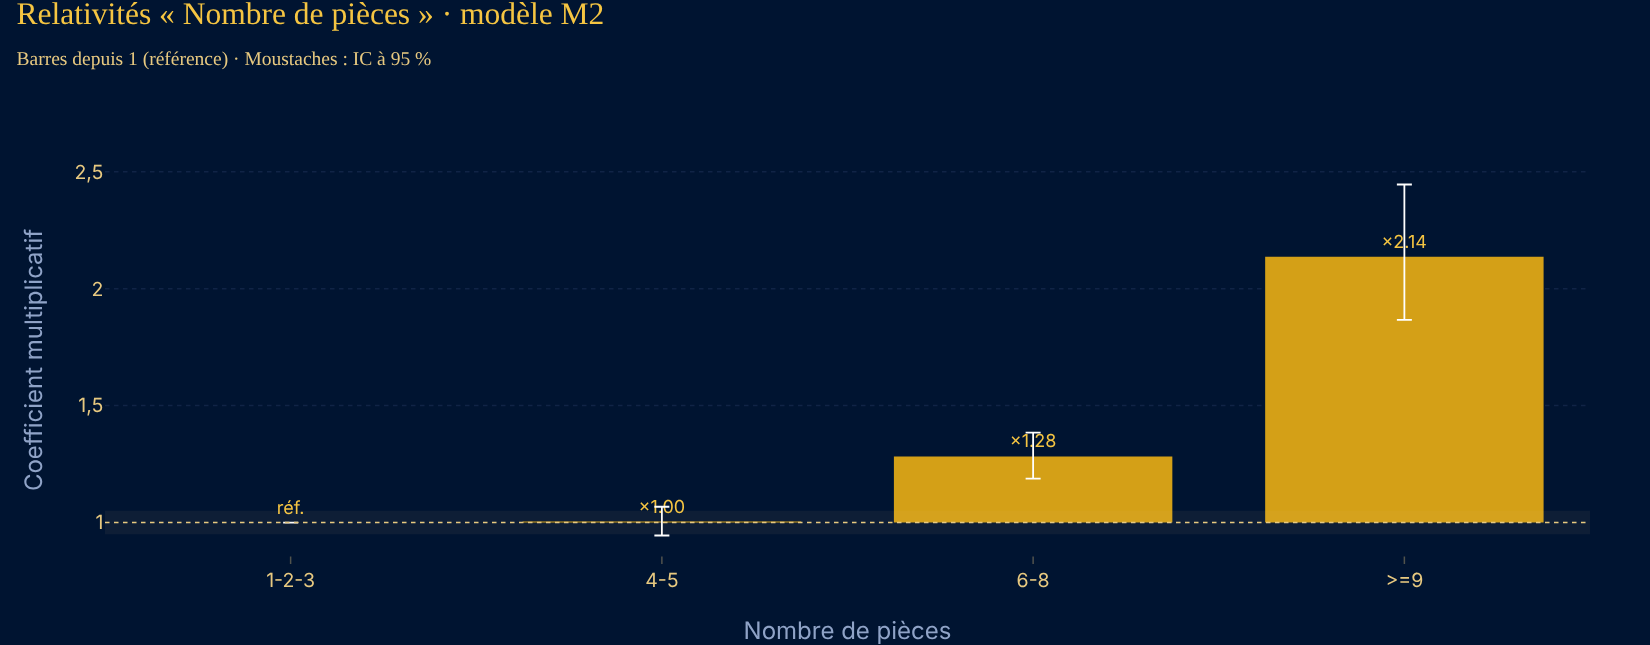

{'Statistique': np.float64(26.92581185234303), 'ddl': 12, 'p-value': 0.007919458436639167}


In [4]:
m1 = M.glm_freq(bda, ["Nbpieces"])
m2 = M.glm_freq(bda, ["Nbpieces", "Nbpers"])
m3 = M.glm_freq(bda, ["Nbpieces", "Nbpers"], interactions=[("Nbpieces", "Nbpers")])
rel = pd.concat({"M1": M.relativites(m1).set_index(["Variable", "Modalité"])["Relativité"],
                 "M2": M.relativites(m2).set_index(["Variable", "Modalité"])["Relativité"]}, axis=1)
display(rel.style.format("{:.3f}", na_rep="-"))
GR.relativites_variable(M.relativites(m2), "Nbpieces", "modèle M2").show()
print(M.test_rapport_vraisemblance(m2, m3))

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> La fréquence est multipliée par ≈ 2,2 pour 9 pièces et plus par rapport à 1-3 pièces ; l'ajout de Nbpers change à peine les relativités de Nbpieces (variables peu liées). Le test du rapport de vraisemblance M2 vs M3 juge l'interaction significative à 5 % (statistique ≈ 27 pour 12 ddl, p ≈ 0,008), mais sur 300 000 lignes le moindre effet devient significatif : il faut regarder les critères pénalisés.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">3. Trois critères de comparaison</h3>

- **AIC** $= -2\log L + 2k$ : vraisemblance pénalisée par le nombre de paramètres.
- **BIC** $= -2\log L + k\log n$ : pénalité plus forte sur les grandes bases, favorise les modèles parcimonieux.
- **RMSE et déviance sur la base test** : qualité de prédiction hors échantillon (critère du cours : RMSE pondérée par l'exposition).

,Modèle,Nb paramètres,Déviance,AIC,BIC,RMSE test,Déviance test
0,M0 · nul,1,"45,808.4","56,491.0","56,501.6",0.176893,"124,127.0"
1,M1 · Nbpieces,4,"45,655.5","56,344.1","56,386.5",0.176553,"123,814.9"
2,M2 · + Nbpers,8,"45,624.0","56,320.5","56,405.4",0.176210,"123,737.3"
3,M3 · + interaction,20,"45,597.0","56,317.6","56,529.8",0.176105,"123,756.3"
4,M4 · complet,35,"44,451.3","55,201.9","55,573.3",0.174474,"120,637.0"


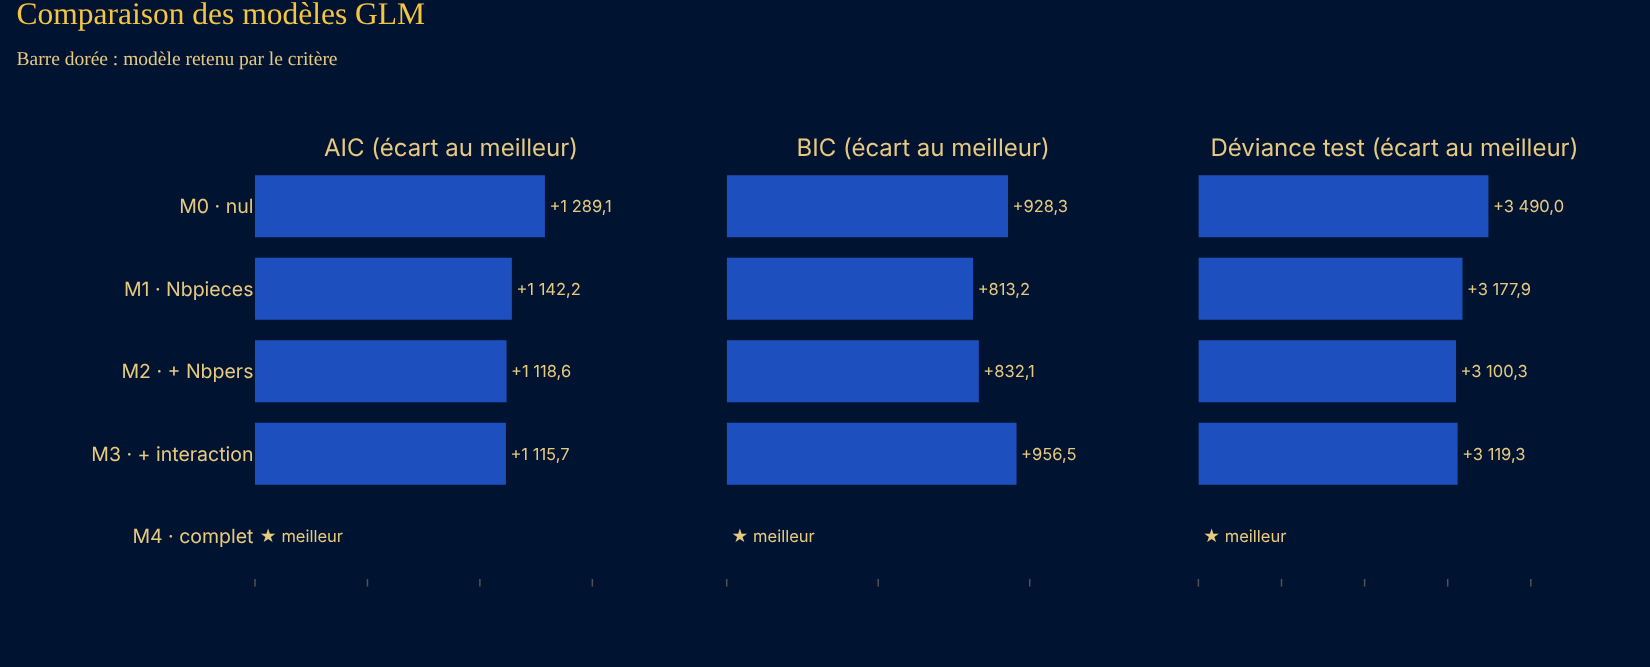

In [5]:
complet = M.glm_freq(bda, VAR_TARIF_DDE)
crit = M.criteres({"M0 · nul": m0, "M1 · Nbpieces": m1, "M2 · + Nbpers": m2, "M3 · + interaction": m3,
                   "M4 · complet": complet}, bdt)
display(crit.style.format({"Déviance": "{:,.1f}", "AIC": "{:,.1f}", "BIC": "{:,.1f}", "RMSE test": "{:.6f}",
                           "Déviance test": "{:,.1f}"}))
GR.comparaison_modeles(crit, ("AIC", "BIC", "Déviance test")).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Chaque variable ajoutée fait baisser la déviance. L'interaction ne gagne que 3 points d'AIC pour 12 paramètres de plus, le BIC la rejette nettement et la déviance test progresse à peine : on ne la retient pas. Le modèle complet domine sur tous les critères, y compris sur la base test : l'information supplémentaire n'est pas du sur-apprentissage.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">4. Modèle complet : variables impactantes et anomalies</h3>

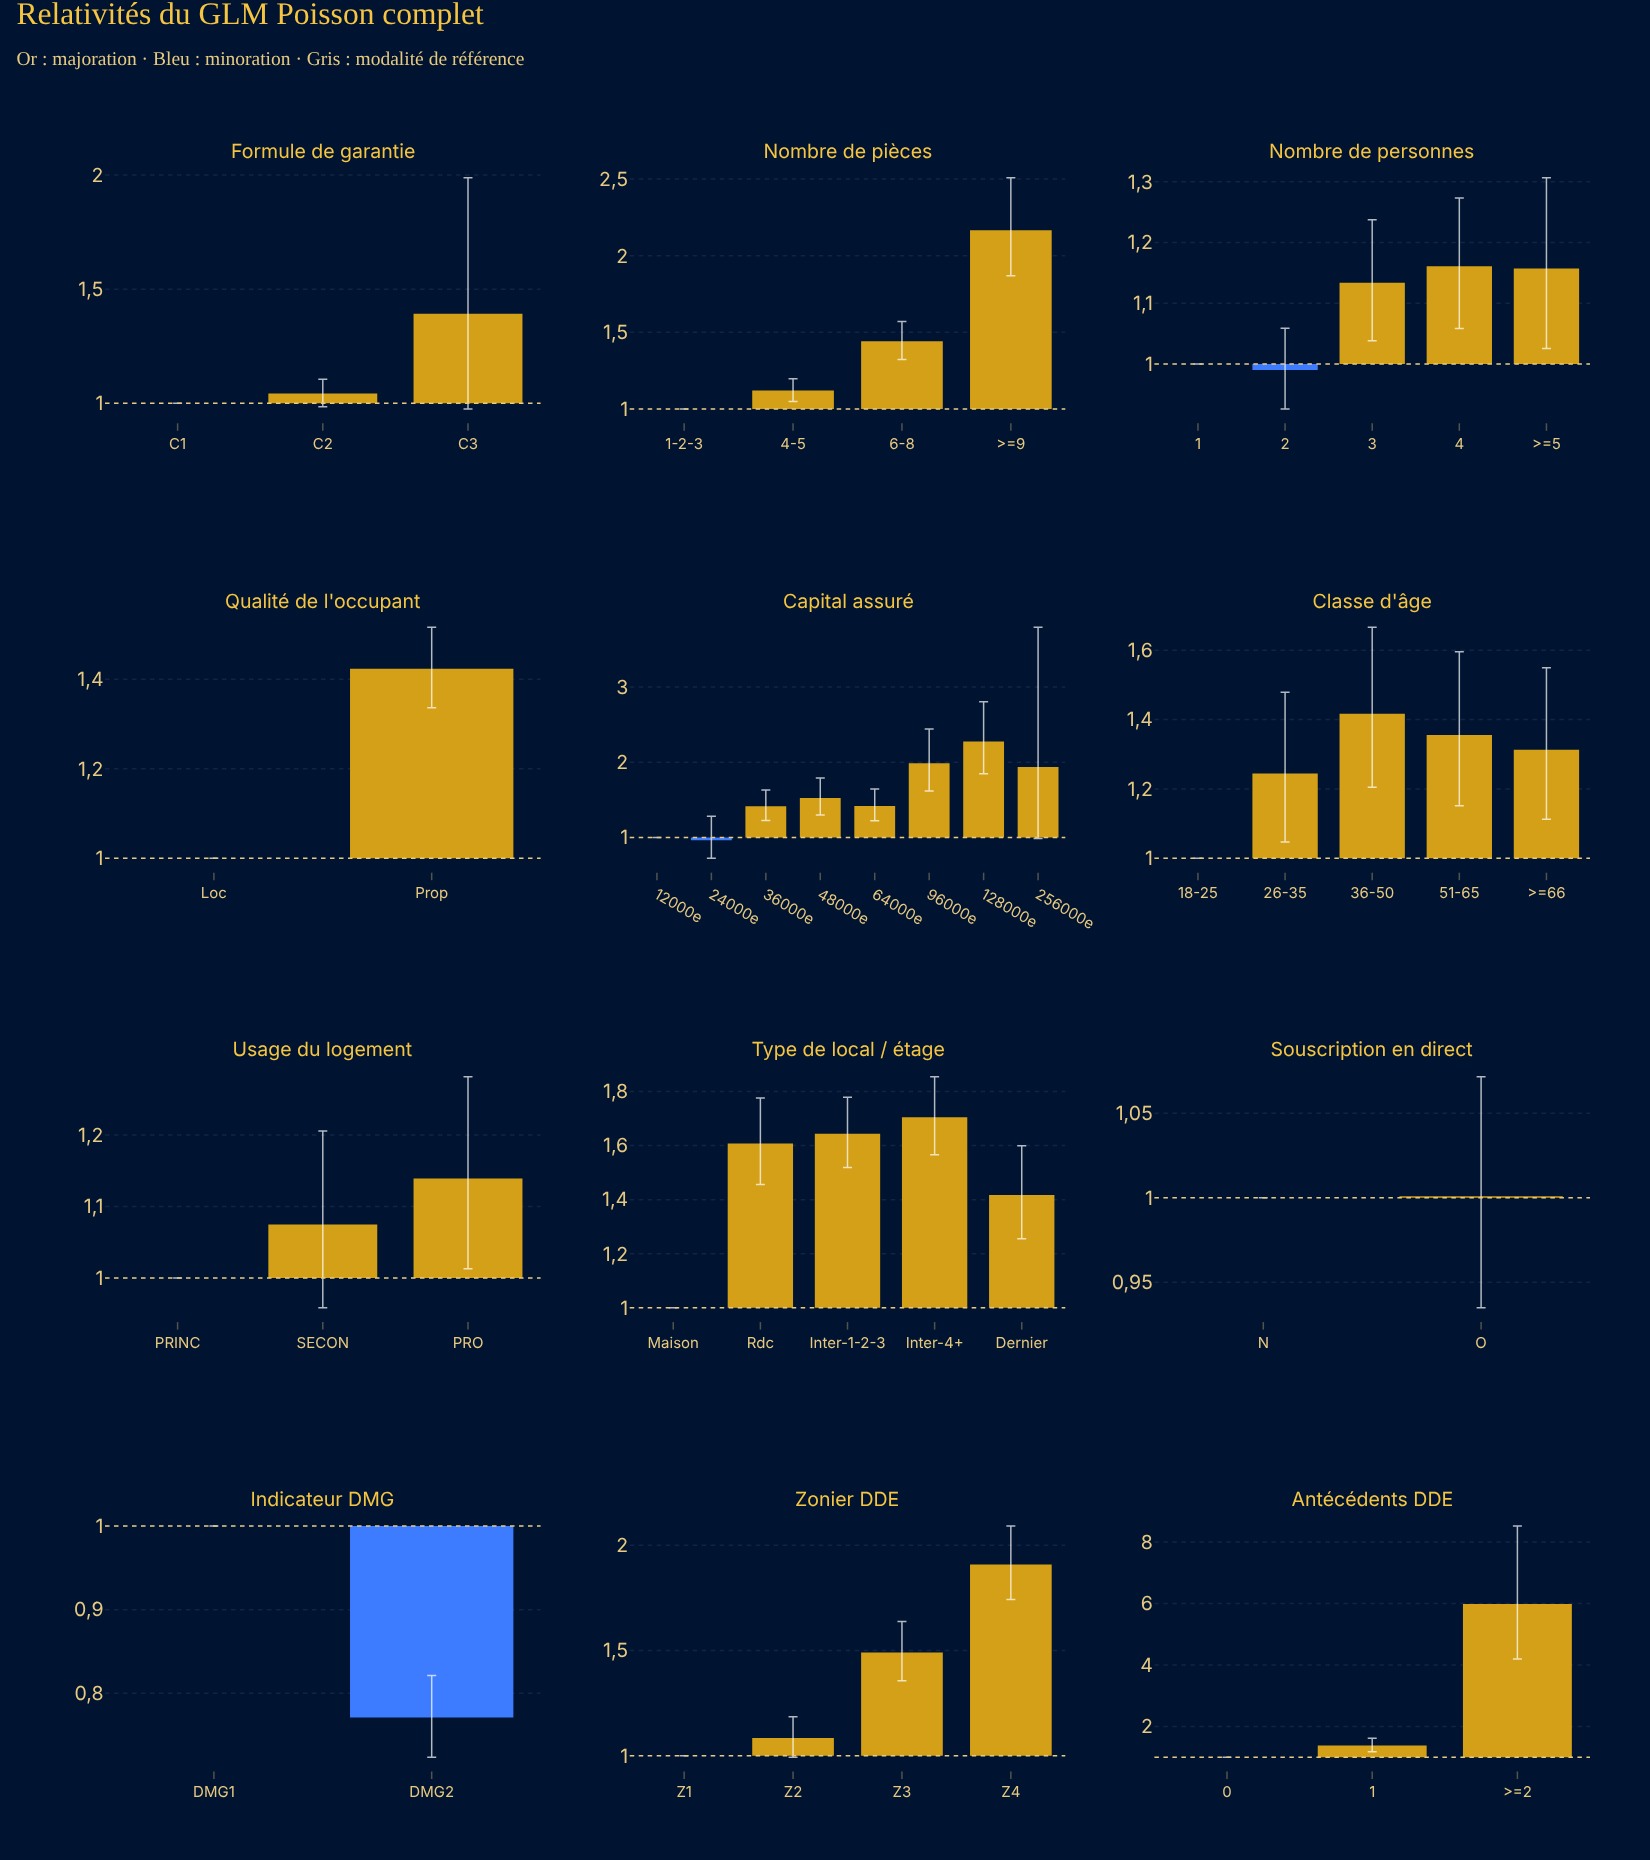

,Variable,Statistique,p-value,ddl
0,Zonier_DDE,317.3,1.76e-68,3
1,Local,241.9,3.62e-51,4
2,Nbpieces,141.1,2.15e-30,3
3,Qualite,120.1,5.89e-28,1
4,Ante_DDE,112.2,4.36e-25,2
5,Kassu,85.7,9.28e-16,7
6,DMG,64.8,8.42e-16,1
7,Nbpers,23.2,1.16e-04,4
8,Age2,23.2,1.18e-04,4
9,Usage,5.9,5.19e-02,2


In [6]:
rel_c = M.relativites(complet)
GR.relativites_grille(rel_c, VAR_TARIF_DDE, "Relativités du GLM Poisson complet").show()
display(M.importance_wald(complet).style.format({"Statistique": "{:.1f}", "p-value": "{:.2e}"}))

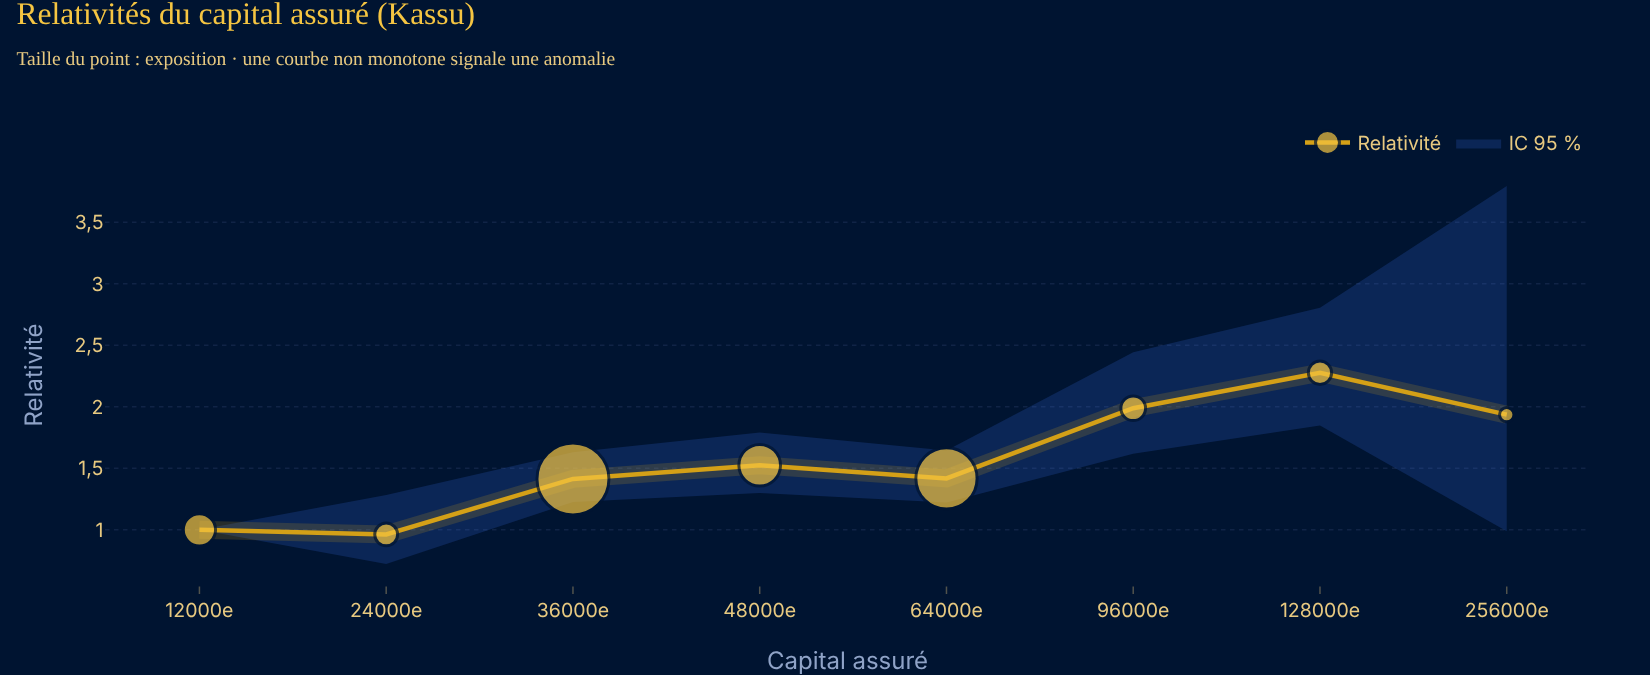

,Modèle,Nb paramètres,Déviance,AIC,BIC,RMSE test,Déviance test
0,Kassu brut,35,"44,451.3463","55,201.9023","55,573.3061",0.1745,"120,637.0067"
1,Kassu regroupé,33,"44,454.0538","55,200.6097","55,550.7905",0.1745,"120,638.8191"


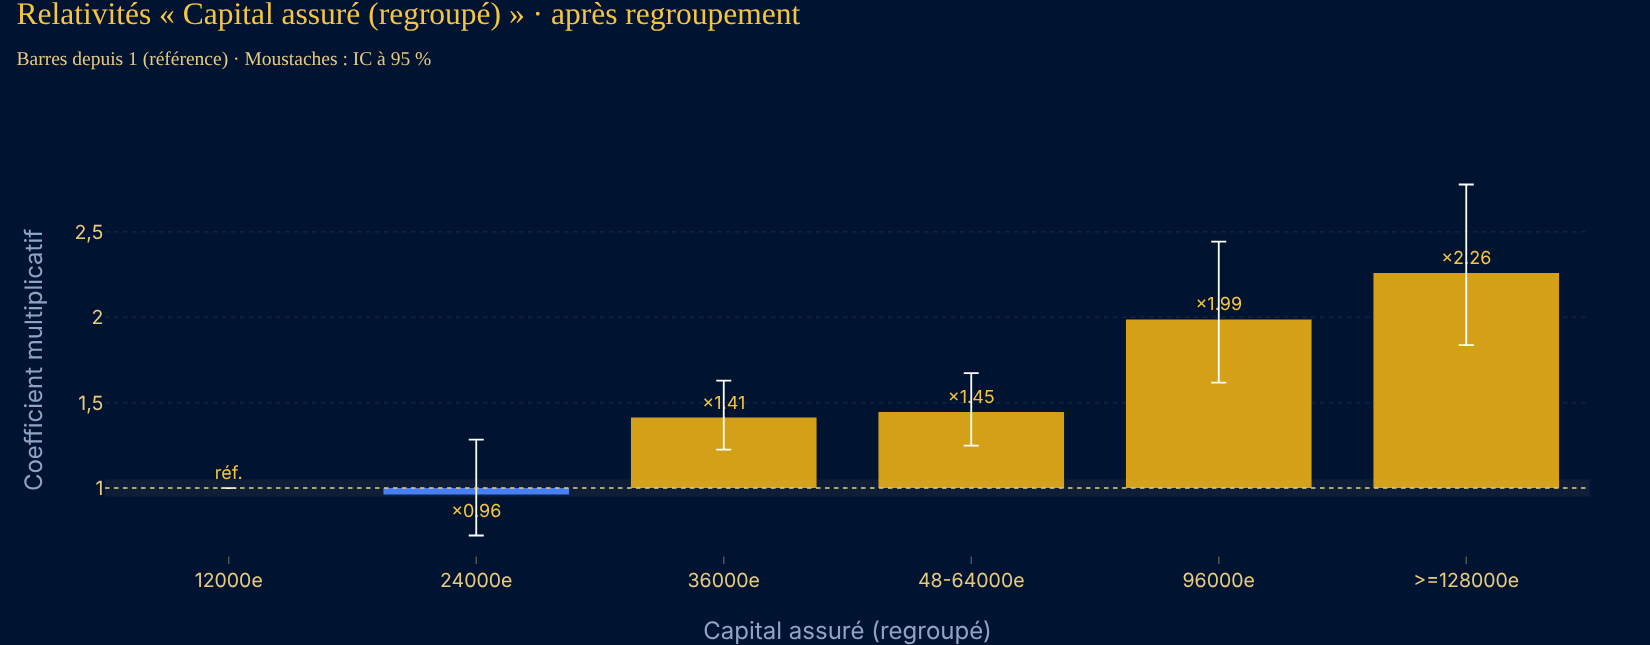

In [7]:
expo_k = bd.groupby("Kassu", observed=True)["Expo"].sum(); expo_k.index = expo_k.index.astype(str)
GR.courbe_kassu(rel_c, expo_k).show()
var_kreg = [v if v != "Kassu" else "Kassu_reg" for v in VAR_TARIF_DDE]
complet_kreg = M.glm_freq(bda, var_kreg)
display(M.criteres({"Kassu brut": complet, "Kassu regroupé": complet_kreg}, bdt))
GR.relativites_variable(M.relativites(complet_kreg), "Kassu_reg", "après regroupement").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> **Variables les plus impactantes** (test de Wald) : Zonier_DDE, Local, Nbpieces, Qualite, puis Ante_DDE, Kassu et DMG.
**Anomalies opérationnelles** : (1) la relativité du capital assuré n'est **pas monotone** (48 000 € > 64 000 €) et
256 000 € a un intervalle de confiance très large : un tarif ne peut pas baisser quand le capital augmente, d'où le
regroupement 48-64 000 € et ≥ 128 000 €, qui améliore à la fois l'AIC et le BIC (le cours propose aussi un lissage) ; (2) **Direct** est sans effet ;
(3) **C3** n'est pas significatif faute d'exposition ; (4) **DMG2** baisse fortement la fréquence sans définition
métier claire : à documenter avant de l'utiliser.</div>

<h2 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercice IV · Importance des variables</h2>

Les calculs pas à pas demandent environ 300 ajustements de GLM sur 300 000 lignes (plusieurs minutes). Mettre `RECALCULER = True` pour tout relancer ; sinon on relit les résultats produits par `scripts/entrainer_modeles.py`, qui utilise exactement les mêmes fonctions.

In [8]:
RECALCULER = False
MOD = Path.cwd().parent / "models"
if RECALCULER:
    imp = M.importance_retrait(bda, VAR_TARIF_DDE)
    inter = M.importance_interactions(bda, VAR_TARIF_DDE, VAR_INTERACTIONS)
    sel_b, hist_b = M.selection_pas_a_pas(bda, VAR_TARIF_DDE, sens="backward")
    sel_f, hist_f = M.selection_pas_a_pas(bda, VAR_TARIF_DDE, sens="forward")
else:
    imp = pd.read_parquet(MOD / "ex4_importance_retrait.parquet")
    inter = pd.read_parquet(MOD / "ex4_interactions.parquet")
    hist_b = pd.read_parquet(MOD / "ex4_backward.parquet")
    hist_f = pd.read_parquet(MOD / "ex4_forward.parquet")

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">1. Variables triées par importance (retrait une à une)</h3>

,Variable,Δ Déviance,Δ AIC,ddl,p-value
0,Zonier_DDE,312.5,306.5,3,1.93e-67
1,Local,238.5,230.5,4,1.94e-50
2,Nbpieces,129.9,123.9,3,5.68e-28
3,Qualite,121.9,119.9,1,2.44e-28
4,Kassu,84.4,70.4,7,1.78e-15
5,Ante_DDE,72.4,68.4,2,1.89e-16
6,DMG,62.7,60.7,1,2.41e-15
7,Age2,24.5,16.5,4,6.40e-05
8,Nbpers,22.9,14.9,4,1.34e-04
9,Usage,5.7,1.7,2,5.67e-02


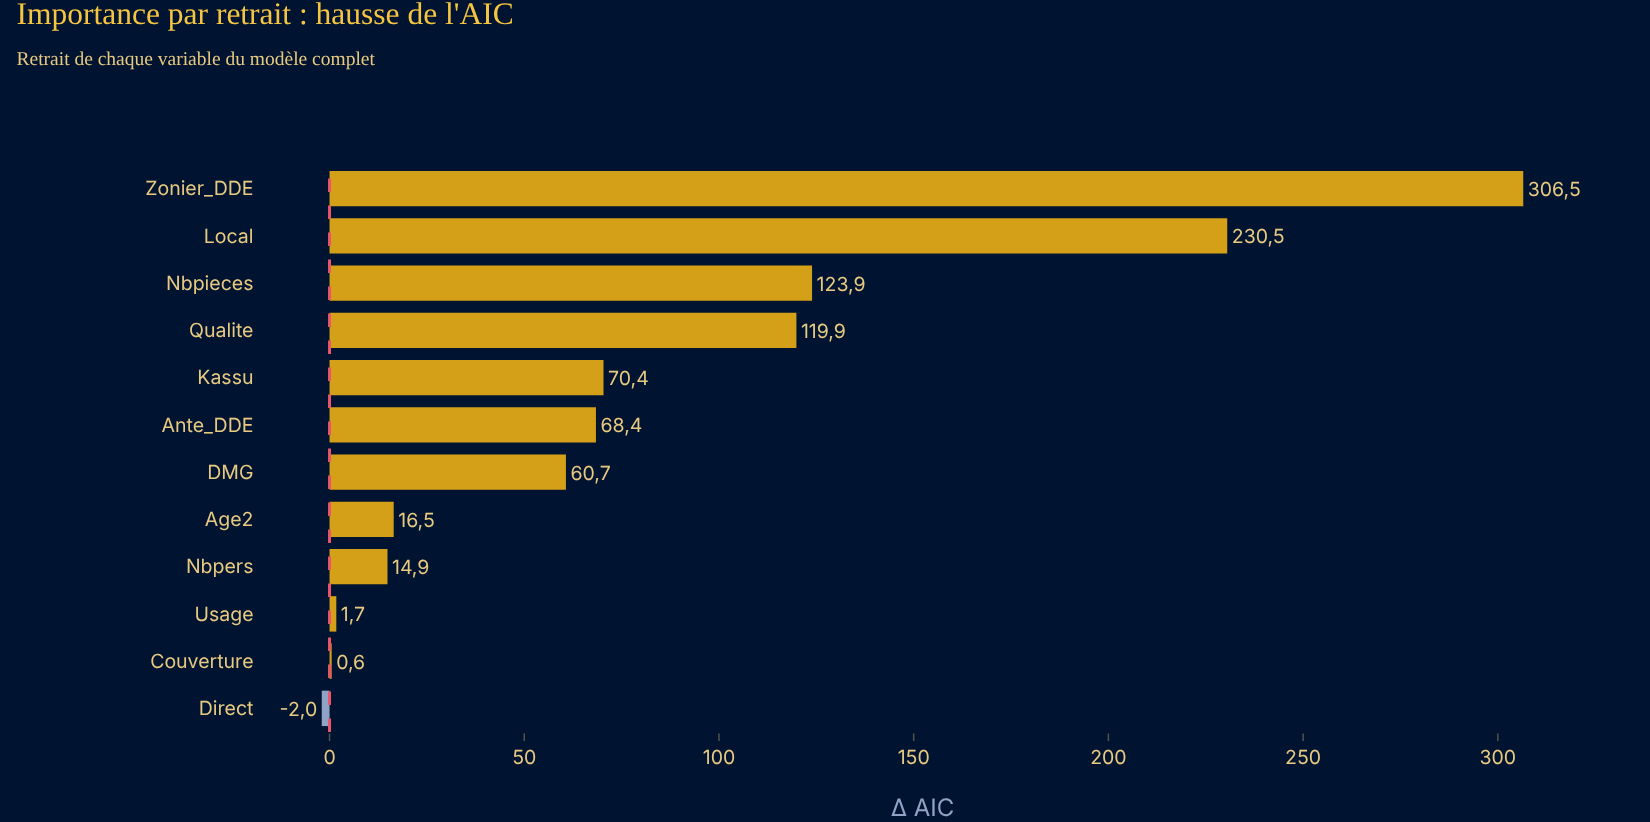

In [9]:
display(imp.style.format({"Δ Déviance": "{:,.1f}", "Δ AIC": "{:,.1f}", "p-value": "{:.2e}"}))
GR.importance_barres(imp, "Variable", "Δ AIC", "Importance par retrait : hausse de l'AIC",
                     "Retrait de chaque variable du modèle complet", seuil=0).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Le classement par déviance et par AIC est le même que celui du test de Wald. Les variables dont le retrait fait **baisser** l'AIC (Δ AIC < 0) n'apportent pas assez d'information pour justifier leurs paramètres.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">2. Interactions triées par significativité</h3>

,Interaction,Δ Déviance,Δ AIC,ddl,p-value
0,Qualite × Zonier_DDE,26.0,-20.0,3,9.50e-06
1,Nbpieces × Qualite,16.5,-10.5,3,8.88e-04
2,Qualite × Local,16.5,-8.5,4,2.39e-03
3,Nbpieces × Zonier_DDE,25.0,-7.0,9,2.96e-03
4,Nbpieces × Nbpers,25.8,-1.8,12,1.13e-02
5,Zonier_DDE × Ante_DDE,12.1,-0.1,6,5.92e-02
6,Nbpers × Zonier_DDE,22.7,1.3,12,2.99e-02
7,Nbpers × Qualite,6.6,1.4,4,1.60e-01
8,Local × Zonier_DDE,20.9,3.1,12,5.14e-02
9,Qualite × Ante_DDE,0.2,3.8,2,8.94e-01


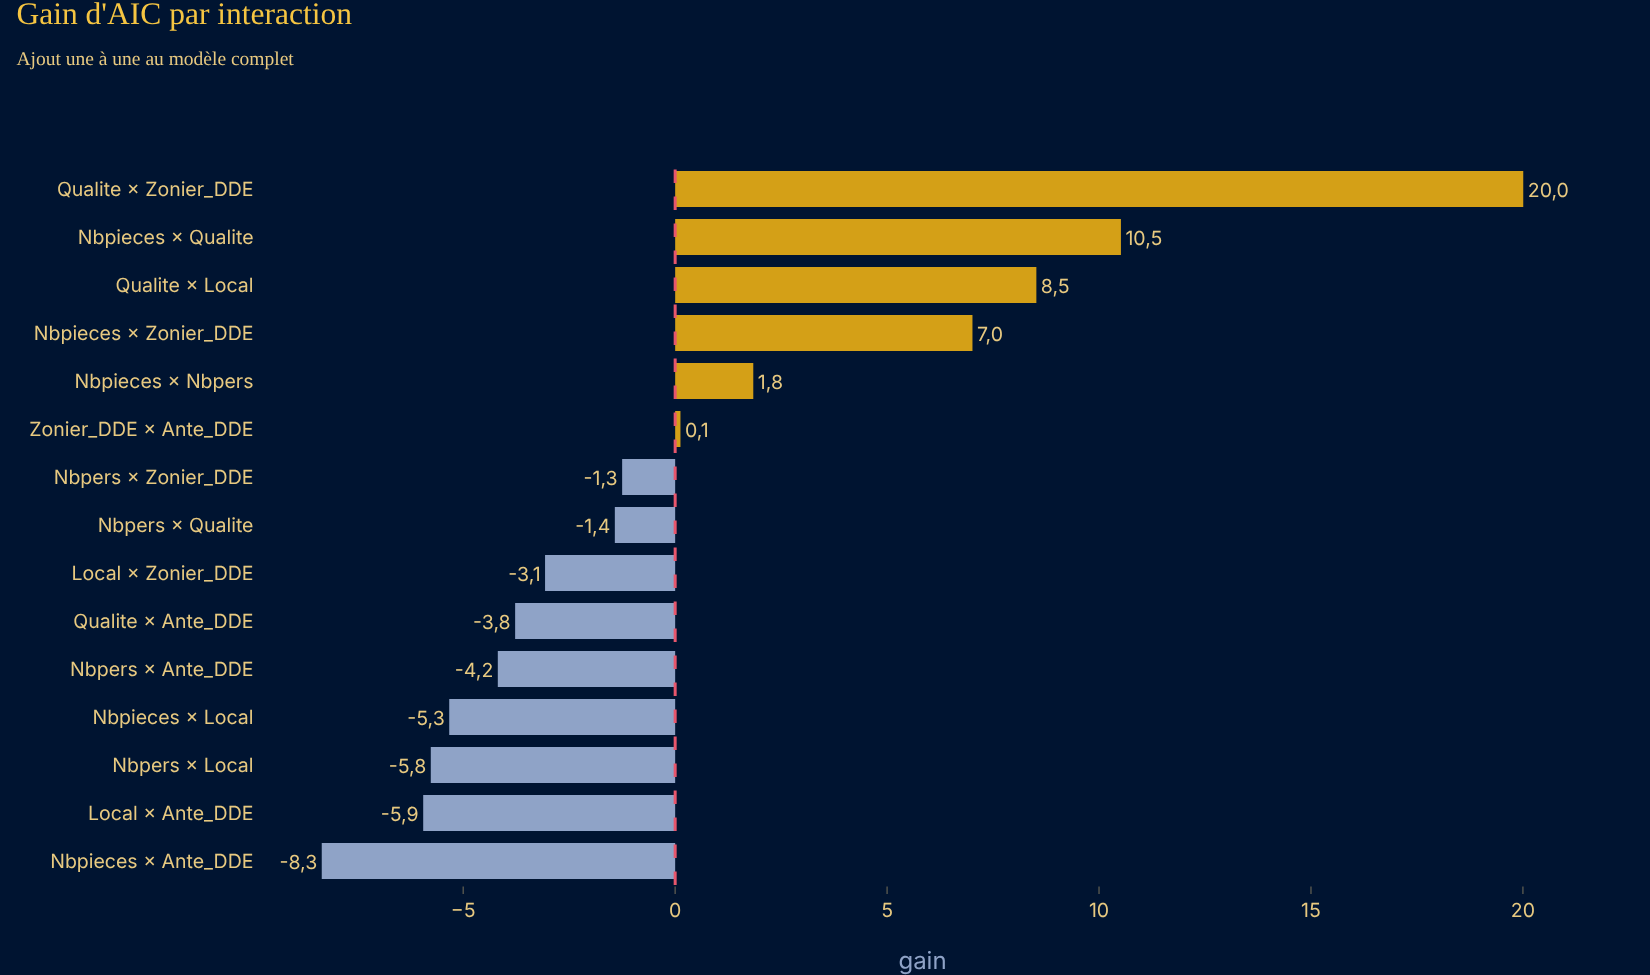

In [10]:
display(inter.style.format({"Δ Déviance": "{:,.1f}", "Δ AIC": "{:,.1f}", "p-value": "{:.2e}"}))
GR.importance_barres(inter.assign(gain=-inter["Δ AIC"]), "Interaction", "gain", "Gain d'AIC par interaction",
                     "Ajout une à une au modèle complet", seuil=0).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Quelques interactions améliorent l'AIC, mais de peu au regard de leur nombre de paramètres. En tarification, une interaction impose une grille croisée, plus difficile à expliquer et moins stable : on ne la retient que si le gain est net et le sens métier évident.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">3. Backward vs forward</h3>

,Étape,Action,Variable,Critère,Nb variables
0,0,Départ (modèle complet),-,"55,201.9023",12
1,1,Retrait,Direct,"55,199.9030",11


,Étape,Action,Variable,Critère,Nb variables
0,0,Départ (modèle nul),-,"56,490.9772",0
1,1,Ajout,Zonier_DDE,"55,951.4662",1
2,2,Ajout,Nbpieces,"55,758.6065",2
3,3,Ajout,Local,"55,602.2004",3
4,4,Ajout,Qualite,"55,446.8221",4
5,5,Ajout,Ante_DDE,"55,374.0025",5
6,6,Ajout,Kassu,"55,304.4419",6
7,7,Ajout,DMG,"55,240.8182",7
8,8,Ajout,Age2,"55,218.0070",8
9,9,Ajout,Nbpers,"55,202.3774",9


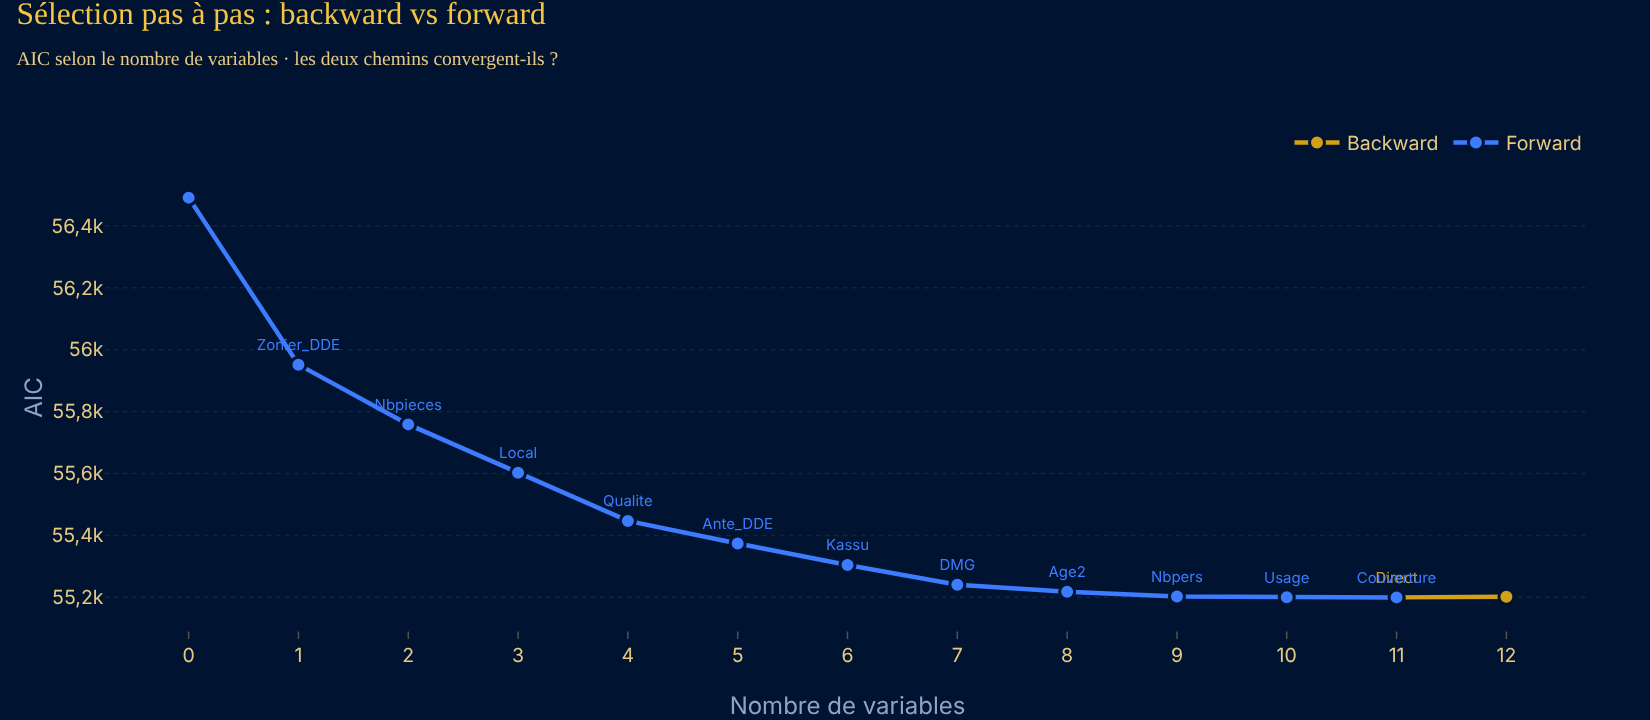

In [11]:
display(hist_b); display(hist_f)
GR.trajectoire_selection(hist_b, hist_f).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Le **backward** part du modèle complet et retire à chaque étape la variable dont le retrait diminue le plus l'AIC ;
le **forward** part du modèle nul et ajoute la variable la plus utile. Ici les deux méthodes convergent vers le même
modèle à 11 variables (seul **Direct** est écarté), ce qui le rend robuste. Le backward évalue chaque variable en présence de toutes les autres (préférable quand
les variables sont liées) ; le forward est plus économe mais peut manquer une variable utile seulement en combinaison.</div>